### Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is an unsupervised dimensionality reduction technique that shrinks a dataset with many variables into a smaller set of new, uncorrelated variables called principal components while keeping as much information (variance) as possible

$$OR$$

**Principal Component Analysis (PCA)** is an unsupervised dimensionality-reduction technique. It transforms a dataset with many possibly correlated features into a smaller set of new features called **principal components**, while retaining as much of the original data variance as possible.

PCA does not select the original columns. Each principal component is a **weighted linear combination of the original features**.

For a dataset \(X\), a component can be written as:

$
PC_1 = w_1X_1 + w_2X_2 + \cdots + w_pX_p
$

Here, the weights \(w_i\) are called **loadings**.

#### Why use PCA?

- Reduce the number of dimensions and potentially reduce computation time.
- Remove redundancy caused by correlated features.
- Help visualize high-dimensional data in 2D or 3D.
- Sometimes reduce noise and improve the performance of distance-based models such as KNN.

PCA is unsupervised: it does not use the target labels when finding components. Therefore, the directions with the highest variance are not guaranteed to be the most useful for predicting the target.

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv('Datasets/train.csv')

In [3]:
df.shape

(42000, 785)

In [4]:
df.sample(3)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
393,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
41381,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
10991,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


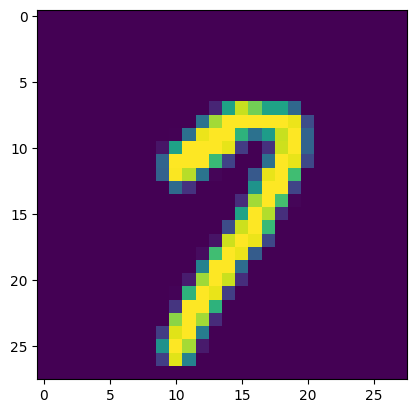

In [5]:
plt.imshow(df.iloc[393, 1:].values.reshape(28,28))

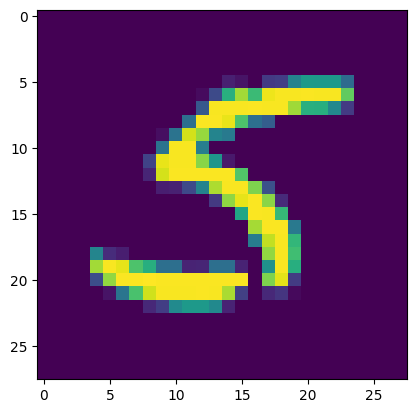

In [6]:
plt.imshow(df.iloc[41381, 1:].values.reshape(28,28))

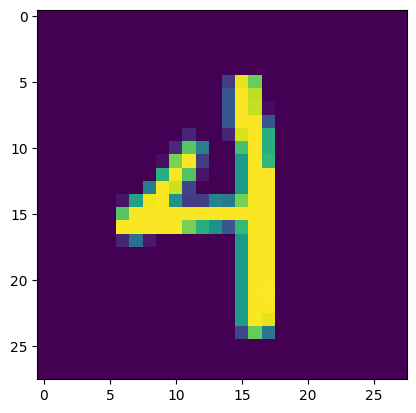

In [7]:
plt.imshow(df.iloc[10991, 1:].values.reshape(28,28))

In [8]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [10]:
X_train.shape

(33600, 784)

In [11]:
y_train.shape

(33600,)

In [12]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train,y_train)

KNeighborsClassifier()

In [13]:
import time
start = time.time()
y_pred = knn.predict(X_test)
print(time.time() - start)

24.966506481170654


In [14]:
from sklearn.metrics import accuracy_score
print("Accuaracy Before PCA : ",accuracy_score(y_test,y_pred))

Accuaracy Before PCA :  0.9648809523809524


**Why scale before PCA ?**

PCA is based on variance. Features with larger numerical scales can dominate the principal components. `StandardScaler` transforms each feature to approximately zero mean and unit variance:

$
z = \frac{x-\mu}{\sigma}
$

Fit the scaler only on training data, then use the same fitted scaler to transform test data. This avoids leaking information from the test set into preprocessing.

In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

**Applying PCA**

`PCA(n_components=200)` asks Scikit-learn to retain the first 200 principal components. These are **not the 200 best original pixel columns**. Each component combines information from many or all input pixels.

Important parameters:

- `n_components`: number of components to keep, or a variance-retention threshold when using a float between 0 and 1 with a suitable solver.
- `svd_solver`: method used to calculate the decomposition; `auto` lets Scikit-learn choose.
- `whiten`: optionally scales component outputs to unit variance; it is not required for ordinary PCA use.

`fit_transform()` learns the components from training data and transforms it. `transform()` applies those already-learned components to test data.

In [16]:
# PCA :-> take 200 best feature
from sklearn.decomposition import PCA
pca = PCA(n_components=200)

In [17]:
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [18]:
X_train_trf.shape

(33600, 200)

In [19]:
knn = KNeighborsClassifier()

In [20]:
knn.fit(X_train_trf,y_train)

KNeighborsClassifier()

In [21]:
y_pred = knn.predict(X_test_trf)

In [22]:
print("Accuracy Socre After PCA (200 best features) : ",accuracy_score(y_test,y_pred))

Accuracy Socre After PCA (200 best features) :  0.9507142857142857


#### How to choose the number of components

This loop explores different component counts and records KNN accuracy. The highest-scoring component count is a candidate for the model.

**Important evaluation note:** this current loop evaluates every candidate on `X_test` and uses those test scores to choose `n_components`. That makes the test set part of model selection, so the final test score becomes optimistically biased. A better workflow is:

1. Split the training data into a fitting subset and a validation subset (or use cross-validation).
2. Fit PCA only on the fitting subset.
3. Evaluate each component count on validation data.
4. Select the best count.
5. Refit the scaler, PCA, and KNN using all training data.
6. Evaluate once on the untouched test set.

The `patience` early-stopping rule is only a speed shortcut; accuracy is not guaranteed to improve or decline monotonically as components are added.

In [23]:
# Here this loop try all combos
best_score = -1.0
best_n = None
no_improve_count = 0
patience = 5

for i in range(1, 785):
    pca = PCA(n_components=i)
    X_train_trf = pca.fit_transform(X_train)
    X_test_trf = pca.transform(X_test)

    knn = KNeighborsClassifier()
    knn.fit(X_train_trf, y_train)

    y_pred = knn.predict(X_test_trf)
    score = accuracy_score(y_test, y_pred)

    print(f"{i}. {score:.4f}")

    if score > best_score:
        best_score = score
        best_n = i
        no_improve_count = 0
    else:
        no_improve_count += 1
        if no_improve_count >= patience:
            print(
                f"Stopping early at n_components={i}. "
                f"Best accuracy: {best_score:.4f} at n_components={best_n}"
            )
            break

1. 0.2581
2. 0.3237
3. 0.5105
4. 0.6663
5. 0.7379
6. 0.8227
7. 0.8437
8. 0.8721
9. 0.8865
10. 0.9056
11. 0.9117
12. 0.9185
13. 0.9276
14. 0.9351
15. 0.9385
16. 0.9380
17. 0.9407
18. 0.9400
19. 0.9425
20. 0.9443
21. 0.9438
22. 0.9442
23. 0.9443
24. 0.9457
25. 0.9485
26. 0.9480
27. 0.9479
28. 0.9471
29. 0.9490
30. 0.9492
31. 0.9507
32. 0.9513
33. 0.9500
34. 0.9505
35. 0.9510
36. 0.9519
37. 0.9518
38. 0.9527
39. 0.9533
40. 0.9529
41. 0.9523
42. 0.9523
43. 0.9524
44. 0.9533
Stopping early at n_components=44. Best accuracy: 0.9533 at n_components=39


In [24]:
# transforming to a 2D coordinate system
pca = PCA(n_components=2)
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

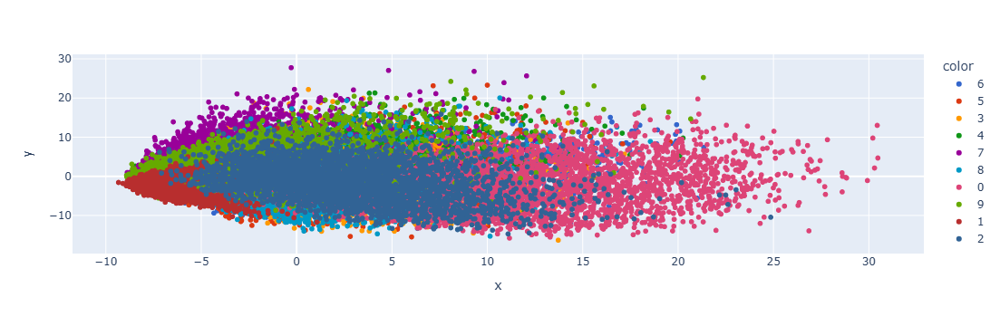

In [25]:
import plotly.express as px
y_train_trf = y_train.astype(str)
fig = px.scatter(x=X_train_trf[:,0],
                 y=X_train_trf[:,1],
                 color=y_train_trf,
                 color_discrete_sequence=px.colors.qualitative.G10
                )
fig.show()

In [26]:
# transforming in 3D
pca = PCA(n_components=3)
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [27]:
X_train_trf

array([[-2.71863253, -0.48982409,  1.1354966 ],
       [-0.67698015, -6.75362491, -2.33590139],
       [-3.03323281,  6.50981624,  7.49182983],
       ...,
       [ 2.14883643,  0.78079444, -0.74738774],
       [ 1.05957006,  0.94767312,  3.94973114],
       [17.70258446,  1.96188185, -4.94352837]])

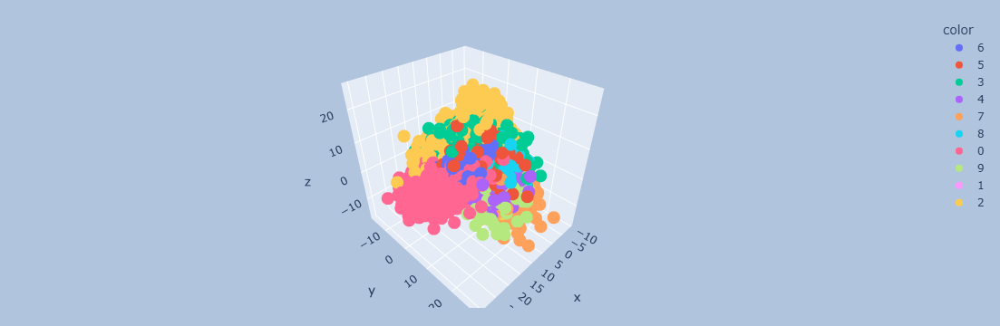

In [28]:
import plotly.express as px
y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=X_train_trf[:,0], y=X_train_trf[:,1], z=X_train_trf[:,2],
              color=y_train_trf)
fig.update_layout(
    margin=dict(l=20, r=20, t=20, b=20),
    paper_bgcolor="LightSteelBlue",
)
fig.show()

#### Eigenvalues, Eigenvectors, and Explained variance ratio

PCA is built from eigen-directions of the data's covariance structure:

- **Eigenvectors** define the directions of the principal components. In Scikit-learn, `components_` stores these directions (as rows).
- **Eigenvalues** measure the variance captured along those directions. In Scikit-learn, `explained_variance_` stores them.
- **Explained variance ratio** tells what fraction of total variance each component explains.

The first component captures the greatest possible variance; each following component captures the greatest remaining variance while being orthogonal to the previous components.

In [29]:
# Eigen values
pca.explained_variance_

array([40.67111198, 29.17023401, 26.74459621])

In [30]:
# Eigen vectors
pca.components_.shape

(3, 784)

In [31]:
pca.explained_variance_ratio_

array([0.05785192, 0.0414927 , 0.03804239])

#### Keeping components using explained variance

`PCA(n_components=None)` calculates all available components. The cumulative explained variance is the running total of the variance ratios:

$
\text{Cumulative variance}(k)=\sum_{i=1}^{k}\text{Explained variance ratio}_i
$

For example, if the first $(k)$ components explain 0.95, they retain 95% of the variance in the scaled training data.

A common starting point is to inspect thresholds such as 90%, 95%, or 99%, then validate model performance. These are guidelines, not universal rules: retaining 95% of variance does not guarantee 95% predictive accuracy.

In [32]:
pca = PCA(n_components=None)
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [33]:
pca.explained_variance_.shape

(784,)

In [34]:
pca.components_.shape

(784, 784)

In [35]:
np.cumsum(pca.explained_variance_ratio_)

array([0.05785192, 0.09934462, 0.13738701, 0.16704964, 0.19286525,
       0.21541506, 0.23514574, 0.25289854, 0.26858504, 0.28294568,
       0.29664822, 0.30892077, 0.32038989, 0.33162017, 0.34220546,
       0.35240477, 0.36198153, 0.37140862, 0.38053351, 0.38943521,
       0.39783462, 0.40603525, 0.41388828, 0.42145568, 0.42882829,
       0.43584714, 0.44282633, 0.44953738, 0.45593583, 0.4622392 ,
       0.46839271, 0.4744166 , 0.48025334, 0.48603881, 0.49176214,
       0.49722614, 0.50265822, 0.50793994, 0.51307376, 0.51801392,
       0.52289063, 0.52771041, 0.53239246, 0.53698588, 0.54156249,
       0.54605468, 0.5505015 , 0.55491691, 0.55926803, 0.56358836,
       0.56780645, 0.57198888, 0.57606882, 0.58008887, 0.58407223,
       0.58801822, 0.59188694, 0.59571889, 0.59948441, 0.60322635,
       0.60687487, 0.6104829 , 0.61402176, 0.61750117, 0.62094441,
       0.62432378, 0.62767368, 0.63099377, 0.63426257, 0.63746765,
       0.64065542, 0.64376931, 0.64686564, 0.64992395, 0.65296

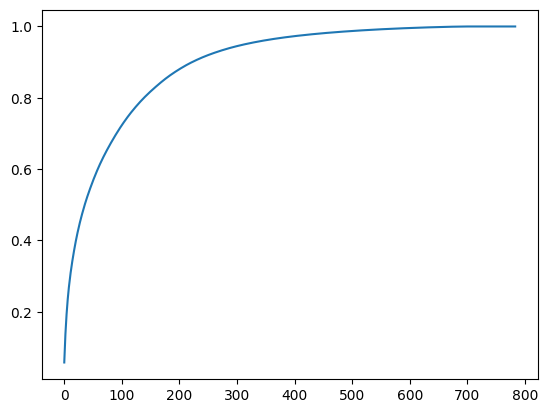

In [36]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))

### Choosing a useful feature combination and PCA workflow

#### What is the “best feature combination”?

PCA creates combinations of the original features using learned weights (loadings). There is no single universally best combination. The best number and combination of components depend on the dataset and the prediction task.

Use these checks together:

1. **Explained variance:** inspect the cumulative explained-variance curve and look for a practical point of diminishing returns (the elbow).
2. **Validation performance:** compare candidate component counts using cross-validation or a validation set with the actual model metric.
3. **Efficiency:** consider training/prediction time and memory, not accuracy alone.
4. **Interpretability:** if explaining individual original features is important, PCA may make the model harder to interpret.

#### Related PCA concepts

- **Dimensionality reduction :** representing data with fewer columns.
- **Principal components :** new, mutually orthogonal axes formed from weighted combinations of original features.
- **Loadings :** weights showing how strongly each original feature contributes to a component.
- **Explained variance ratio :** proportion of variance captured by each component.
- **Cumulative explained variance :** total variance retained by the first \(k\) components.
- **Scree plot / elbow method :** plot component number against explained variance to identify diminishing returns.
- **Whitening :** optional rescaling of component scores to unit variance.
- **Inverse transform :** approximately reconstruct original features from retained components; reconstruction loses information when components are discarded.